In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Устанавливаем seed для воспроизводимости
np.random.seed(42)

# Количество объектов
n_samples = 1000

# 1. Этаж (случайные целые числа от 1 до 30)
floors = np.random.randint(1, 31, size=n_samples)

# 2. Площадь в м2 (распределена нормально, например, в среднем 60 м2 со стандартным отклонением 20 м2, ограничим снизу 20 м2)
areas = np.random.normal(loc=60, scale=20, size=n_samples)
areas = np.clip(areas, 20, 200) # Ограничиваем площадь разумными рамками

# 3. Стоимость в тысячах (зависит от площади и немного от этажа + случайный шум)
# Базовая цена за м2, например, 150 тысяч рублей
base_price_per_m2 = 150
price = areas * base_price_per_m2 + (floors * 10) + np.random.normal(0, 500, size=n_samples)
# Ограничим минимальную стоимость, чтобы не было отрицательных значений
price = np.clip(price, 1500, None)

# Объединяем в матрицу (размерностью 3 на 1000)
data_matrix = np.array([floors, areas, price])

# Для удобства также создадим DataFrame
df = pd.DataFrame(data_matrix.T, columns=['Floor', 'Area_m2', 'Price_thousands'])

# Выведем первые несколько строк и размерность матрицы
print("Размерность матрицы:", data_matrix.shape)
print("\nПервые 5 строк датафрейма:")
print(df.head(100))

Размерность матрицы: (3, 1000)

Первые 5 строк датафрейма:
    Floor    Area_m2  Price_thousands
0     7.0  53.739526      7504.634369
1    20.0  28.017531      4151.398339
2    29.0  32.628198      5324.819435
3    15.0  70.709836     10293.665005
4    11.0  81.208936     12612.184161
..    ...        ...              ...
95   29.0  91.640764     14514.334723
96   18.0  52.238616      7703.397657
97   26.0  46.631961      7668.719143
98   12.0  87.914639     13303.674408
99    2.0  33.807014      5747.256441

[100 rows x 3 columns]


In [ ]:
import numpy as np

# Подготовим признаки (X) и целевую переменную (y)
# Признаки: Этаж и Площадь
X_raw = df[['Floor', 'Area_m2']].values

# Добавляем вектор единиц для свободного члена (bias / intercept)
ones = np.ones((X_raw.shape[0], 1))
X = np.hstack((ones, X_raw))

# Целевая переменная: Стоимость
y = df['Price_thousands'].values

# Вычисляем веса по формуле w = (X^T * X)^(-1) * X^T * y
w = np.linalg.inv(X.T @ X) @ X.T @ y

# Выводим коэффициенты
print("Полученный вектор весов w:")
print(f"w_0 (свободный член): {w[0]:.4f}")
print(f"w_1 (вес для этажа): {w[1]:.4f}")
print(f"w_2 (вес для площади): {w[2]:.4f}")

Полученный вектор весов w:
w_0 (свободный член): -4.5878
w_1 (вес для этажа): 8.3038
w_2 (вес для площади): 150.3982


In [ ]:
import numpy as np

# Задаем параметры тестового объекта: [1 (bias), этаж=7, площадь=55]
x_test = np.array([1.0, 7.0, 55.0])

# Предсказываем стоимость с помощью скалярного произведения (веса w уже рассчитаны ранее)
predicted_price = x_test @ w

print(f"Характеристики объекта:")
print(f"- Этаж: {x_test[1]:.0f}")
print(f"- Площадь: {x_test[2]:.0f} м2")
print(f"\nПредсказанная стоимость квартиры: {predicted_price:.2f} тысяч рублей")

Характеристики объекта:
- Этаж: 7
- Площадь: 55 м2

Предсказанная стоимость квартиры: 8325.44 тысяч рублей


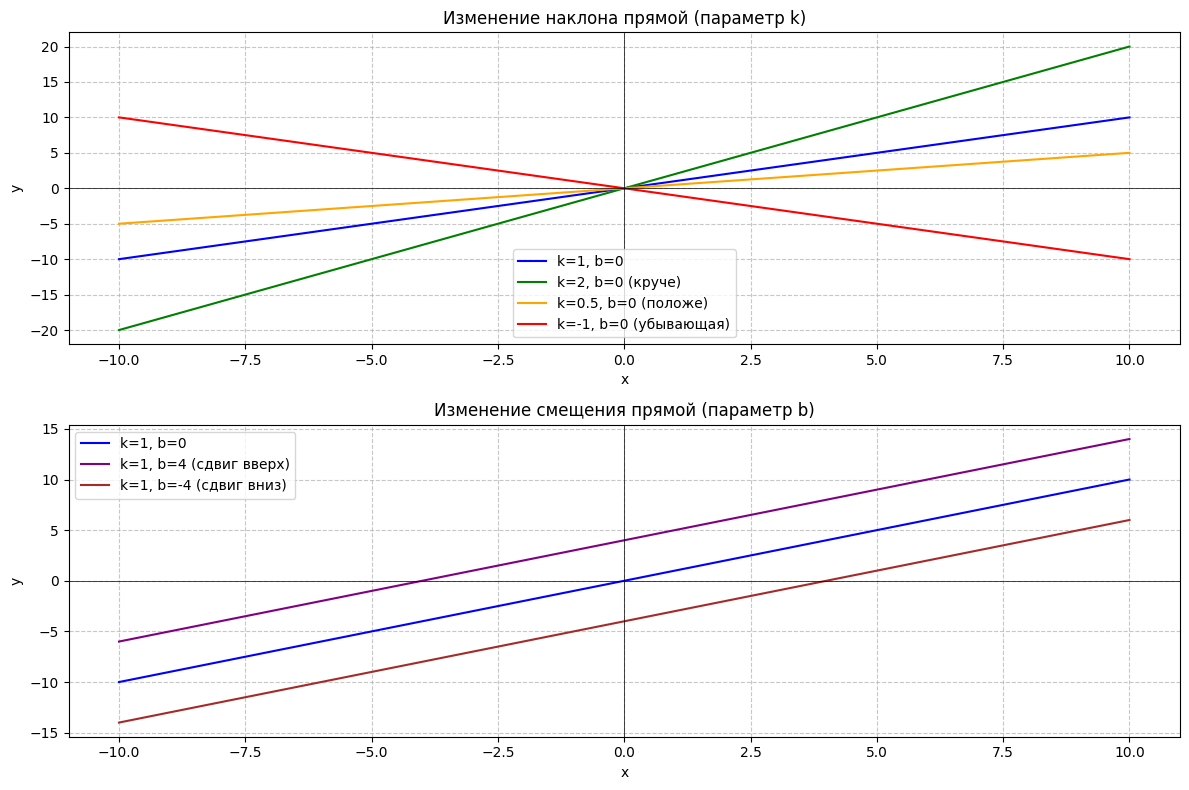

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# Определяем диапазон для x
x = np.linspace(-10, 10, 400)

plt.figure(figsize=(12, 8))

# 1. Меняем наклон k при фиксированном b = 0
plt.subplot(2, 1, 1)
plt.plot(x, 1*x + 0, label='k=1, b=0', color='blue')
plt.plot(x, 2*x + 0, label='k=2, b=0 (круче)', color='green')
plt.plot(x, 0.5*x + 0, label='k=0.5, b=0 (положе)', color='orange')
plt.plot(x, -1*x + 0, label='k=-1, b=0 (убывающая)', color='red')
plt.axhline(0, color='black', linewidth=0.5)
plt.axvline(0, color='black', linewidth=0.5)
plt.title('Изменение наклона прямой (параметр k)')
plt.xlabel('x')
plt.ylabel('y')
plt.grid(True, linestyle='--', alpha=0.7)
plt.legend()

# 2. Меняем смещение b при фиксированном k = 1
plt.subplot(2, 1, 2)
plt.plot(x, 1*x + 0, label='k=1, b=0', color='blue')
plt.plot(x, 1*x + 4, label='k=1, b=4 (сдвиг вверх)', color='purple')
plt.plot(x, 1*x - 4, label='k=1, b=-4 (сдвиг вниз)', color='brown')
plt.axhline(0, color='black', linewidth=0.5)
plt.axvline(0, color='black', linewidth=0.5)
plt.title('Изменение смещения прямой (параметр b)')
plt.xlabel('x')
plt.ylabel('y')
plt.grid(True, linestyle='--', alpha=0.7)
plt.legend()

plt.tight_layout()
plt.show()



y = <wx> + w0